# F1: orbital phase of JDFTx projections (implemented)

**Finding** (`notes/theory_audit.md`, F1): JDFTx builds atomic orbitals without the $i^l$ factor of the plane-wave
expansion. Each dumped projection is therefore $(-i)^l$ times the projection onto the real orbital, and
$\mathrm{Re}[T^*_u T_v]$ is about zero for pairs with odd $l_u - l_v$ (s–p, p–d). Those interactions were
missing from every pair spectrum.

**Fix:** crawfish multiplies JDFTx projections by $i^l$ on load. **Legacy switch:** `legacy_orbital_phase=True`.

This notebook compares legacy and fixed crawfish on the N2 test calculation (molecule along x). It also checks the
fixed pCOMO against the reference implementation in `fixcompare.py`. pCOMO uses no matrix, so it is the one
spectrum F1 alone should make exactly right. pCOHP signs still have F2's problems (see
`F2_signed_matrices.ipynb`). Figures are saved to `figures/`. The last cell holds the tests.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixcompare import *
from crawfish.funcs.general import SIGMA_DEFAULT
from crawfish.funcs import get_pcohp, get_ipcohp, get_pcomo, get_ipcomo
from crawfish.funcs.pcohp import _get_pcomo_tj

assert fix_available("F1")
edata_legacy = load_edata(legacy_orbital_phase=True)
edata_fixed = load_edata()
ref = Reference(edata_fixed)
A = lambda orbs: orb_idcs(edata_fixed, 0, orbs)
B = lambda orbs: orb_idcs(edata_fixed, 1, orbs)
PAIRS = [("s", "s"), ("s", "px"), ("px", "px"), ("py", "py")]
SIG = SIGMA_DEFAULT
erange = np.arange(edata_fixed.e_tj.min() - 0.03, edata_fixed.e_tj.max() + 0.03, 0.0005, dtype=np.float32)
x_ev = to_ev_rel_mu(edata_fixed, erange)
GAMMA = [t for t in range(edata_fixed.nstates) if np.allclose(edata_fixed.ks_t[t], 0)][0]

## Projections at Γ

At Γ the Kohn–Sham states are real up to a per-band phase. For real orbitals, $T^*_{s,A}T_{p_x,B}$ must then be
real. In legacy mode it is purely imaginary instead.

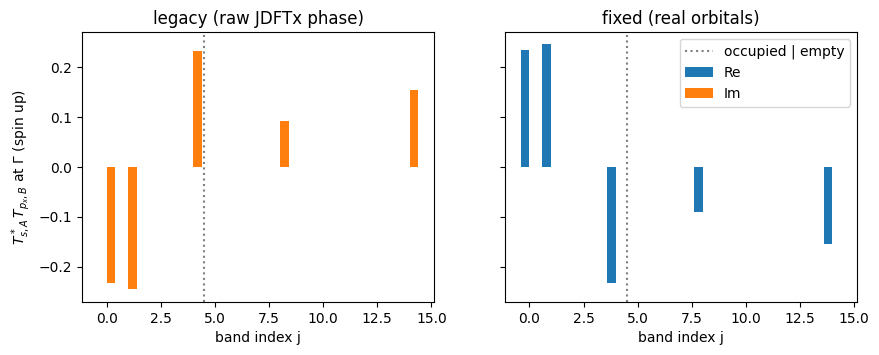

In [2]:
s_A, px_B = A("s")[0], B("px")[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (name, ed) in zip(axes, [("legacy (raw JDFTx phase)", edata_legacy), ("fixed (real orbitals)", edata_fixed)]):
    prod = np.conj(ed.proj_tju[GAMMA, :, s_A]) * ed.proj_tju[GAMMA, :, px_B]
    j = np.arange(len(prod))
    ax.bar(j - 0.2, prod.real, 0.4, label="Re")
    ax.bar(j + 0.2, prod.imag, 0.4, label="Im")
    ax.axvline(np.sum(edata_fixed.occ_tj[GAMMA] > 0.5) - 0.5, color="gray", linestyle=":", label="occupied | empty")
    ax.set_title(name)
    ax.set_xlabel("band index j")
axes[0].set_ylabel(r"$T^*_{s,A}\,T_{p_x,B}$ at $\Gamma$ (spin up)")
axes[1].legend()
savefig(fig, "F1_gamma_s_px_products")
plt.show()

## pCOMO spectra

pCOMO = Σ Re[C*_u C_v] δ(E − ε) has no matrix factor. After F1 it should equal the reference exactly (dashed).

loading from /Users/richb/vs/crawfish/src/../tests/files/io/example_calc_dirs/N2_bare_min/.crawfish_cache/lgph_True_lou_True_h-en_True_p-c_True_trimj_False


loading from /Users/richb/vs/crawfish/src/../tests/files/io/example_calc_dirs/N2_bare_min/.crawfish_cache/lgph_False_lou_True_h-en_True_p-c_True_trimj_False


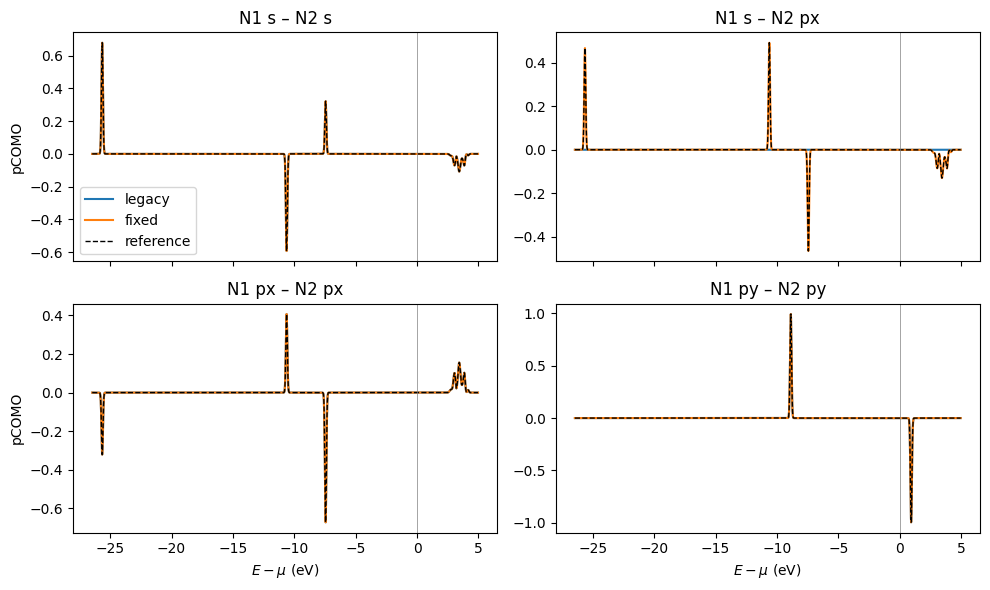

In [3]:
def spectrum(func, ed, o1, o2):
    _, spec = func(ed, idcs1=0, idcs2=1, orbs1=o1, orbs2=o2, erange=erange, sig=SIG,
                   use_cache=False, use_cached_spectrum=False, save_spectrum=False)
    return np.asarray(spec)

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, (o1, o2) in zip(axes.ravel(), PAIRS):
    ax.plot(x_ev, spectrum(get_pcomo, edata_legacy, o1, o2), label="legacy")
    ax.plot(x_ev, spectrum(get_pcomo, edata_fixed, o1, o2), label="fixed")
    ax.plot(x_ev, reference_spectrum(edata_fixed, ref.weights_tj(A(o1), B(o2), "como"), erange, SIG),
            "k--", lw=1, label="reference")
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(f"N1 {o1} – N2 {o2}")
for ax in axes[1]:
    ax.set_xlabel(r"$E - \mu$ (eV)")
for ax in axes[:, 0]:
    ax.set_ylabel("pCOMO")
axes[0, 0].legend()
fig.tight_layout()
savefig(fig, "F1_pcomo_spectra")
plt.show()

## pCOHP spectra

These are plotted as −pCOHP, so bonding is positive. F1 brings back the s–px contribution. Because of F2, the
pCOHP signs and magnitudes are still not the target values.

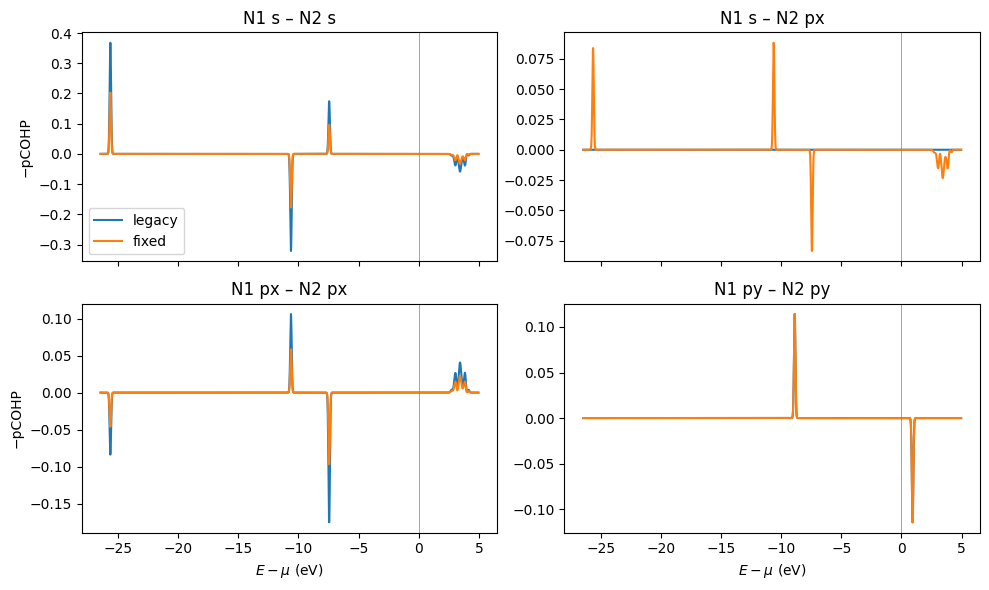

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, (o1, o2) in zip(axes.ravel(), PAIRS):
    ax.plot(x_ev, -spectrum(get_pcohp, edata_legacy, o1, o2), label="legacy")
    ax.plot(x_ev, -spectrum(get_pcohp, edata_fixed, o1, o2), label="fixed")
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(f"N1 {o1} – N2 {o2}")
for ax in axes[1]:
    ax.set_xlabel(r"$E - \mu$ (eV)")
for ax in axes[:, 0]:
    ax.set_ylabel("−pCOHP")
axes[0, 0].legend()
fig.tight_layout()
savefig(fig, "F1_pcohp_spectra")
plt.show()

## Integrated values (up to the Fermi level)

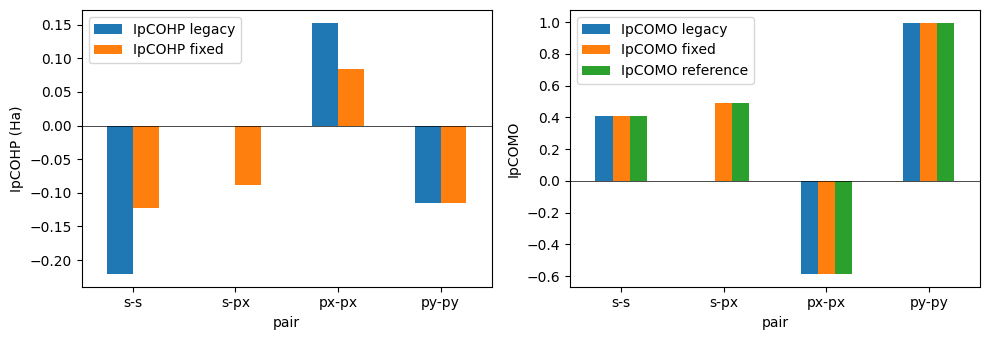

,IpCOHP legacy,IpCOHP fixed,IpCOMO legacy,IpCOMO fixed,IpCOMO reference
pair,,,,,
s-s,-0.22098,-0.12203,0.40719,0.40719,0.40719
s-px,0.00000,-0.08856,-0.00000,0.49230,0.49230
px-px,0.15313,0.08452,-0.58770,-0.58770,-0.58770
py-py,-0.11463,-0.11462,0.99778,0.99778,0.99778


In [5]:
rows = []
for o1, o2 in PAIRS:
    kw = dict(idcs1=0, idcs2=1, orbs1=o1, orbs2=o2, use_cache=False)
    rows.append({
        "pair": f"{o1}-{o2}",
        "IpCOHP legacy": last_value(get_ipcohp(edata_legacy, **kw)),
        "IpCOHP fixed": last_value(get_ipcohp(edata_fixed, **kw)),
        "IpCOMO legacy": last_value(get_ipcomo(edata_legacy, **kw)),
        "IpCOMO fixed": last_value(get_ipcomo(edata_fixed, **kw)),
        "IpCOMO reference": ref.integrated(A(o1), B(o2), "como"),
    })
table = pd.DataFrame(rows).set_index("pair")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
table[["IpCOHP legacy", "IpCOHP fixed"]].plot.bar(ax=axes[0], rot=0)
table[["IpCOMO legacy", "IpCOMO fixed", "IpCOMO reference"]].plot.bar(ax=axes[1], rot=0)
axes[0].set_ylabel("IpCOHP (Ha)")
axes[1].set_ylabel("IpCOMO")
for ax in axes:
    ax.axhline(0, color="black", lw=0.5)
fig.tight_layout()
savefig(fig, "F1_integrated")
plt.show()
table.round(5)

## Tests

In [6]:
# 1. Gamma s-px products: imaginary in legacy, real after the fix
for ed, part in [(edata_legacy, "real"), (edata_fixed, "imag")]:
    prod = np.conj(ed.proj_tju[GAMMA, :, s_A]) * ed.proj_tju[GAMMA, :, px_B]
    assert np.max(np.abs(prod)) > 0.1
    assert np.max(np.abs(getattr(prod, part))) < 1e-4, part

# 2. pDOS unaffected: |T| identical
assert np.allclose(np.abs(edata_legacy.proj_tju), np.abs(edata_fixed.proj_tju))

# 3. Fixed pCOMO weights equal the reference implementation, for every pair
for o1, o2 in PAIRS:
    w_crawfish = _get_pcomo_tj(edata_fixed, 0, None, o1, 1, None, o2, use_cache=False)
    assert np.allclose(w_crawfish, ref.weights_tj(A(o1), B(o2), "como"), atol=1e-5), (o1, o2)

# 4. Same-l pCOMO is phase-independent; s-px was ~0 before the fix
for pair in ["s-s", "px-px", "py-py"]:
    assert np.isclose(table.loc[pair, "IpCOMO legacy"], table.loc[pair, "IpCOMO fixed"], atol=1e-5), pair
assert abs(table.loc["s-px", "IpCOMO legacy"]) < 1e-4 and abs(table.loc["s-px", "IpCOMO fixed"]) > 0.1

# 5. Legacy reproduces the values recorded before the fix (notes/theory_audit.md, section 6)
recorded = {"s-s": (-0.22098, 0.40719), "s-px": (0.0, 0.0), "px-px": (0.15313, -0.58770), "py-py": (-0.11463, 0.99778)}
for pair, (icohp, icomo) in recorded.items():
    assert np.isclose(table.loc[pair, "IpCOHP legacy"], icohp, atol=2e-5), pair
    assert np.isclose(table.loc[pair, "IpCOMO legacy"], icomo, atol=2e-5), pair
print("All F1 checks passed.")

All F1 checks passed.
